# 01 Hazard models

All of the hazard models in one place. A discrete-time hazard model asks, each month, "given this customer has made
it this far, what is the chance of the event now?" (Allison, 1982; Singer & Willett, 1993). It is fitted as a
logistic-type regression on a **person-month table**: one row per customer per month, instead of one row per customer.

| Model | What changes | Why it is here |
|---|---|---|
| Logit hazard | nothing: the baseline | The industry-standard form; auditable; the model we submit |
| Cloglog hazard | the link | The grouped-time Cox model (Prentice & Gloeckler, 1978); $e^{\beta}$ are hazard ratios |
| Logit hazard, L1 / L2 | a penalty, C tuned on validation | Like Oscar's tuning; tests whether shrinkage helps |
| Cox, time-varying covariates | continuous time | The literature standard (Cox, 1972), on the same rows |

Not built: frailty and the mixture cure model (no Python package with covariates; see `../research/`), AFT,
recurrent-event Cox. The models differ only in a link, a penalty or the fitter, so each is one function in
section 2, and fitting all of them is one cell.

**Data:** the shared cleaned split from `report/01-Data.ipynb` (run that first), reshaped by `prep.py`. Only train and
validation are used; the test set is touched once, at the end, for the chosen model.

## Where the code comes from

| Piece | Source | Reused how |
|---|---|---|
| Binomial GLM with logit / cloglog link, customer-clustered standard errors | statsmodels documentation: [GLM](https://www.statsmodels.org/stable/glm.html), [`GLM.fit` (`cov_type="cluster"`)](https://www.statsmodels.org/stable/generated/statsmodels.genmod.generalized_linear_model.GLM.fit.html) | Library calls as documented |
| Penalised logistic regression | scikit-learn: [`LogisticRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) | Library call; `l1_ratio` picks L1 / L2 (the `penalty` argument is deprecated from 1.8) |
| Cox with time-varying covariates: long layout and fit | lifelines: [*Time varying survival regression*](https://lifelines.readthedocs.io/en/stable/Time%20varying%20survival%20regression.html) (Davidson-Pilon, 2019) | Their layout (`id`, `start`, `stop`, `event`) and call; the October prediction is my own |
| Pseudo R² | statsmodels: [`GLMResults.pseudo_rsquared`](https://www.statsmodels.org/stable/generated/statsmodels.genmod.generalized_linear_model.GLMResults.pseudo_rsquared.html) | Library call |
| Actual-vs-expected event rate by month | Botha & Muller (2025), [doi:10.5281/zenodo.15856389](https://doi.org/10.5281/zenodo.15856389) | Approach only: their code is R, so the comparison here is my own two lines |
| Calibration curve | scikit-learn: [`calibration_curve`](https://scikit-learn.org/stable/modules/generated/sklearn.calibration.calibration_curve.html) | Library call |
| Person-period approach | Allison (1982); [Wheeler (2020), *Discrete time survival models in python*](https://andrewpwheeler.com/2020/09/26/discrete-time-survival-models-in-python/) | Approach only: his code has no licence and expands durations with fixed covariates, so `prep.py` is my own |



In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from lifelines import CoxTimeVaryingFitter
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score

import prep

wide = prep.load_split()                  # train and validation, one row per customer
pm = prep.person_months(wide)             # one row per customer per month, t = 3..7
train, val = pm["train"], pm["validation"]
print({part: df.shape for part, df in pm.items()})
train.head()

{'train': (89985, 21), 'validation': (29995, 21)}


,t,event,util_lag,payratio_lag,log_limit,age,status_lag_-2,status_lag_0,status_lag_1,status_lag_2,...,SEX_2,EDUCATION_2,EDUCATION_3,EDUCATION_4,MARRIAGE_2,MARRIAGE_3,t_4,t_5,t_6,t_7
ID,,,,,,,,,,,,,,,,,,,,,
1,3,0,-1.009947,1.322225,-1.879491,-1.243778,1.0,0.0,0.0,0.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,4,0,-1.009947,1.322225,-1.879491,-1.243778,0.0,0.0,0.0,0.0,...,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,5,1,-0.919041,1.322225,-1.879491,-1.243778,0.0,0.0,0.0,0.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,6,1,-0.600673,1.322225,-1.879491,-1.243778,0.0,0.0,0.0,1.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,7,1,-0.493670,-0.912817,-1.879491,-1.243778,0.0,0.0,0.0,1.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


## 1. The person-month table

| t | 3 | 4 | 5 | 6 | 7 |
|---|---|---|---|---|---|
| Month | Jun | Jul | Aug | Sep | **Oct** |
| Event | 2+ months behind | 2+ behind | 2+ behind | 2+ behind | **the real default label** |
| Covariates from | May | Jun | Jul | Aug | Sep |

Each customer has five rows. Covariates are lagged one month, so a month's own status never predicts itself.
Everyone is at risk every month (customers already behind are kept, unlike Sprint 0), so every customer gets an
October prediction. **The October row is the one scored**: September covariates, October default.

Event rate by month. Only October is a real default; June to September use the "2+ months behind" proxy.

In [2]:
assert (train.groupby(level=0).size() == 5).all()
assert (prep.october(train)["event"] == wide["train"][prep.Y]).all()
train.groupby("t")["event"].agg(rate="mean", events="sum").round(3)

,rate,events
t,,
3,0.119,2149
4,0.141,2539
5,0.148,2659
6,0.104,1873
7,0.221,3981


## 2. The models

$$\text{link}\big(h(t \mid x)\big) = \alpha_t + \beta^\top x_{t-1}$$

* **logit** link: $\log\frac{h}{1-h}$, so $\beta$ are log odds ratios of the monthly hazard.
* **cloglog** link: $\log(-\log(1-h))$, the exact grouped-time Cox model, so $e^{\beta}$ are hazard ratios.
* **penalised**: the logit, minimising the log loss plus an L1 ($\lVert\beta\rVert_1$) or L2 ($\lVert\beta\rVert_2^2$)
  penalty whose weight is $1/C$.
* **Cox**: $h(t \mid x) = h_0(t)\, e^{\beta^\top x_{t-1}}$, each row the interval $(t-1, t]$; the baseline $h_0$
  replaces the month dummies.

$\alpha_t$ is one intercept per month (the month dummies), so the baseline hazard is fully flexible.

In [3]:
LINKS = {"logit": sm.families.links.Logit(), "cloglog": sm.families.links.CLogLog()}


def fit_glm(data, link="logit", cols=None):
    """Discrete-time hazard: a binomial GLM on the person-month rows.

    Standard errors are clustered by customer, because one customer's rows are not
    independent; the coefficients are the same either way.
    """
    cols = cols or prep.features(data)
    model = sm.GLM(data["event"], sm.add_constant(data[cols]), family=sm.families.Binomial(link=LINKS[link]))
    return model.fit(cov_type="cluster", cov_kwds={"groups": data.index.to_numpy()})


def fit_penalised(data, penalty="l2", C=1.0):
    """The logit hazard with a lasso (l1) or ridge (l2) penalty. C small = strong penalty.

    The month dummies are penalised too (scikit-learn cannot exempt them); with 90,000
    rows the shrinkage on them is tiny.
    """
    model = LogisticRegression(C=C, l1_ratio=1.0 if penalty == "l1" else 0.0,
                               solver="liblinear" if penalty == "l1" else "lbfgs", max_iter=2000)
    return model.fit(data[prep.features(data)], data["event"])


def fit_cox(data):
    """Cox model with time-varying covariates, in the lifelines long layout.

    A small ridge penalty and a shorter Newton step stop it diverging: the default step
    gives coefficients of about 45, because the status dummies are nearly separable in
    some months. Ties (thousands of events at each month) are handled by Efron's method.
    """
    cols = prep.features(data, months=False)
    df = data[cols].assign(id=data.index, start=data["t"] - 1, stop=data["t"],
                           event=data["event"].astype(bool)).reset_index(drop=True)
    model = CoxTimeVaryingFitter(penalizer=0.01)
    return model.fit(df, id_col="id", event_col="event", start_col="start", stop_col="stop",
                     fit_options={"step_size": 0.3}, show_progress=False)


def predict_october(model, data):
    """P(default in October) for each customer: the hazard of their t = 7 row.

    Cox has no predict for time-varying fits, so its October hazard is built from the
    baseline: h = 1 - exp(-[H0(7) - H0(6)] * exp((x - mean)'beta)).
    """
    rows = prep.october(data)
    if isinstance(model, CoxTimeVaryingFitter):
        H0 = model.baseline_cumulative_hazard_.iloc[:, 0]
        h0 = H0.loc[prep.OCTOBER] - H0.loc[prep.OCTOBER - 1]
        p = 1 - np.exp(-h0 * model.predict_partial_hazard(rows[model.params_.index]).to_numpy())
    elif isinstance(model, LogisticRegression):
        p = model.predict_proba(rows[model.feature_names_in_])[:, 1]
    else:
        cols = [c for c in model.model.exog_names if c != "const"]
        p = model.predict(sm.add_constant(rows[cols], has_constant="add"))
    return pd.Series(np.asarray(p), index=rows.index, name="probability")


def score(y, p):
    """The headline metrics: ranking (AUC) and probability accuracy (Brier, log loss)."""
    return {"AUC": roc_auc_score(y, p), "Brier": brier_score_loss(y, p), "log loss": log_loss(y, p)}

## 3. Fit every model and score the validation customers' October row

The penalised models use C = 1 here; section 5 tunes it.

In [4]:
models = {
    "logit": fit_glm(train, link="logit"),
    "cloglog": fit_glm(train, link="cloglog"),
    "logit, L1": fit_penalised(train, penalty="l1", C=1.0),
    "logit, L2": fit_penalised(train, penalty="l2", C=1.0),
    "Cox, time-varying": fit_cox(train),
}

y_val = prep.october(val)["event"]
results = pd.DataFrame({name: score(y_val, predict_october(m, val)) for name, m in models.items()}).T
results.round(4)

,AUC,Brier,log loss
logit,0.7438,0.1380,0.4460
cloglog,0.7442,0.1385,0.4502
"logit, L1",0.7438,0.1380,0.4459
"logit, L2",0.7438,0.1380,0.4459
"Cox, time-varying",0.7447,0.1407,0.4597


## 4. Does pooling the months help?

The fair test of the hazard idea: the same logit fitted on the **October rows only** (one row per customer, which is
Oscar's set-up with my features). Any advantage of the hazard model must come from the extra months.

In [5]:
oct_train = prep.october(train)
october_only = fit_glm(oct_train, cols=prep.features(oct_train, months=False))
results.loc["logit, October rows only"] = score(y_val, predict_october(october_only, val))
results.round(4)

,AUC,Brier,log loss
logit,0.7438,0.1380,0.4460
cloglog,0.7442,0.1385,0.4502
"logit, L1",0.7438,0.1380,0.4459
"logit, L2",0.7438,0.1380,0.4459
"Cox, time-varying",0.7447,0.1407,0.4597
"logit, October rows only",0.7503,0.1365,0.4389


## 5. Tuning the penalty

Same function, a grid of C, scored on the validation customers' October row (as Oscar did).

In [6]:
tuning = pd.DataFrame([{"penalty": penalty, "C": C, **score(y_val, predict_october(fit_penalised(train, penalty, C), val))}
                       for penalty in ("l1", "l2") for C in np.logspace(-3, 1, 5)])
tuning.round(4)

,penalty,C,AUC,Brier,log loss
0,l1,0.001,0.7251,0.1447,0.4642
1,l1,0.010,0.7368,0.1382,0.4460
2,l1,0.100,0.7434,0.1379,0.4458
3,l1,1.000,0.7438,0.1380,0.4459
4,l1,10.000,0.7438,0.1380,0.4459
5,l2,0.001,0.7266,0.1409,0.4527
6,l2,0.010,0.7394,0.1380,0.4457
7,l2,0.100,0.7431,0.1379,0.4458
8,l2,1.000,0.7438,0.1380,0.4459
9,l2,10.000,0.7438,0.1380,0.4459


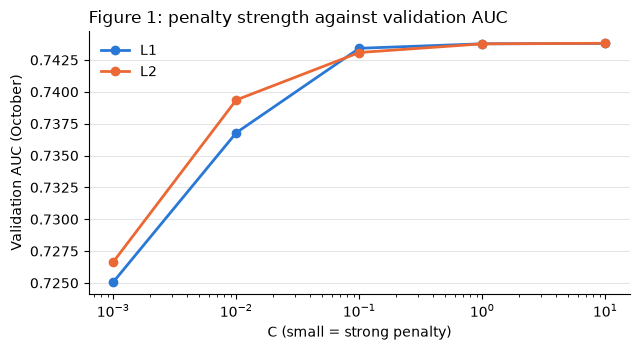

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for penalty, colour in (("l1", "#2a78d6"), ("l2", "#eb6834")):
    sub = tuning[tuning["penalty"] == penalty]
    ax.plot(sub["C"], sub["AUC"], marker="o", markersize=6, linewidth=2, color=colour, label=penalty.upper())
ax.set_xscale("log")
ax.set_xlabel("C (small = strong penalty)")
ax.set_ylabel("Validation AUC (October)")
ax.set_title("Figure 1: penalty strength against validation AUC", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5")
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## 6. Logit against cloglog, clustered standard errors and fit

The two links give near-identical coefficients when hazards are small. The last column checks how much larger the
customer-clustered standard errors are than the naive ones.

In [8]:
logit, cloglog = models["logit"], models["cloglog"]
naive = sm.GLM(logit.model.endog, logit.model.exog, family=logit.model.family).fit()
coefs = pd.DataFrame({"logit": logit.params, "cloglog": cloglog.params,
                      "cloglog hazard ratio": np.exp(cloglog.params),
                      "clustered / naive SE": logit.bse / naive.bse})
coefs.round(3)

,logit,cloglog,cloglog hazard ratio,clustered / naive SE
const,-2.268,-2.270,0.103,0.955
util_lag,0.065,0.034,1.035,0.997
payratio_lag,-0.315,-0.283,0.753,1.032
log_limit,-0.294,-0.200,0.819,0.945
age,0.038,0.024,1.025,0.943
status_lag_-2,-0.671,-0.707,0.493,0.971
status_lag_0,-0.542,-0.432,0.649,1.033
status_lag_1,0.788,0.907,2.477,1.044
status_lag_2,2.656,2.125,8.370,1.042
status_lag_3,3.061,2.292,9.894,1.030


Pseudo R² against an intercept-only model, from statsmodels' `pseudo_rsquared` (McFadden: $1 - \ell_{model}/\ell_{null}$; Cox-Snell: $1 - e^{2(\ell_{null} - \ell_{model})/n}$).

In [9]:
pd.DataFrame({name: {"McFadden": models[name].pseudo_rsquared("mcf"),
                     "Cox-Snell": models[name].pseudo_rsquared("cs")}
              for name in ("logit", "cloglog")}).T.round(3)

,McFadden,Cox-Snell
logit,0.313,0.230
cloglog,0.308,0.226


## 7. Calibration

**By month** (the idea of Botha & Muller's actual-vs-expected term structure, applied to our "everyone at risk every month"
set-up): the mean predicted hazard against the actual event rate, per month, on the validation customers. **In
October** (scikit-learn's `calibration_curve`, ten equal-sized bins): does a predicted 30% mean 30% default?

mean absolute error by month: 0.0006


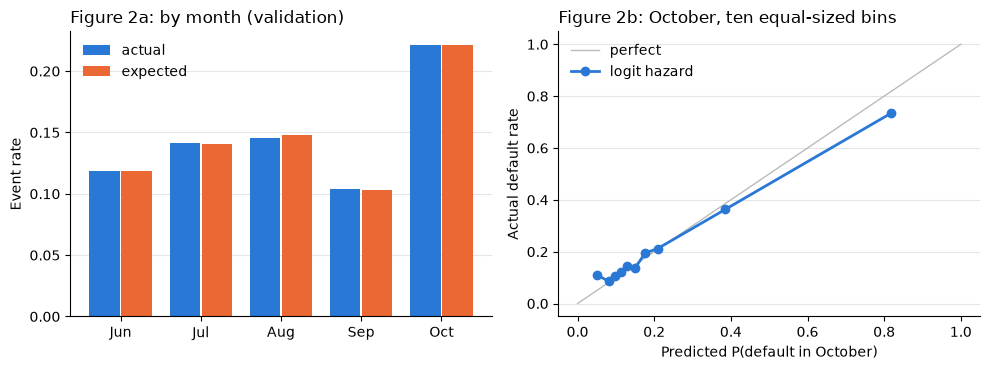

,actual,expected
t,,
3,0.119,0.119
4,0.141,0.140
5,0.146,0.148
6,0.104,0.103
7,0.221,0.221


In [10]:
p_all = pd.Series(np.asarray(logit.predict(sm.add_constant(val[prep.features(val)]))), index=val.index)
term = pd.DataFrame({"actual": val.groupby("t")["event"].mean(), "expected": p_all.groupby(val["t"]).mean()})
print("mean absolute error by month:", round(float((term["actual"] - term["expected"]).abs().mean()), 4))
actual_rate, predicted_rate = calibration_curve(y_val, predict_october(logit, val), n_bins=10, strategy="quantile")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
x = np.arange(len(term))
ax1.bar(x - 0.2, term["actual"], width=0.38, color="#2a78d6", label="actual")
ax1.bar(x + 0.2, term["expected"], width=0.38, color="#eb6834", label="expected")
ax1.set_xticks(x, ["Jun", "Jul", "Aug", "Sep", "Oct"])
ax1.set_ylabel("Event rate")
ax1.set_title("Figure 2a: by month (validation)", loc="left")
ax1.legend(frameon=False)
ax2.plot([0, 1], [0, 1], color="#bbbbbb", linewidth=1, label="perfect")
ax2.plot(predicted_rate, actual_rate, marker="o", markersize=6, linewidth=2, color="#2a78d6", label="logit hazard")
ax2.set_xlabel("Predicted P(default in October)")
ax2.set_ylabel("Actual default rate")
ax2.set_title("Figure 2b: October, ten equal-sized bins", loc="left")
ax2.legend(frameon=False)
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e5e5")
    ax.set_axisbelow(True)
fig.tight_layout()
plt.show()
term.round(3)

## 8. Test-set predictions (run once, when the model is final)

Writes `data/output/predictions-alex.csv` (customer ID and probability), the file the group's metric notebook
scores. Left commented out so the test set is not used while models are still changing.

In [11]:
# pm_test = prep.person_months(prep.load_split(("train", "test")))     # standardised with the training rows
# predict_october(models["logit"], pm_test["test"]).to_csv(prep.ROOT / "data" / "output" / "predictions-alex.csv")

## Notes

* Results are single runs on the validation set. Tuning C on validation and quoting validation scores is optimistic;
  the honest number is the test score of the one chosen model.
* The October baseline (`t_7`) is estimated from the October rows only; the other coefficients are shared across
  months, so they blend "what predicts falling 2+ months behind" (proxy) with "what predicts October default"
  (real). Section 4 shows whether that blend helps.
* Cox: every event happens at one of five times, so the ties approximation is doing a lot of work; the discrete-time
  model is exact for monthly data. That is the reason to prefer it, not the score.
* Clustered standard errors came out at 0.88 to 1.04 times the naive ones on a first run, so within-customer
  dependence barely matters here, probably because last month's status (a covariate) already carries most of it.
  Check this on your own run before quoting it.
* October calibration (Figure 2b) on a first run: too confident at both ends. The lowest tenth was predicted 5% but 11% defaulted; the top tenth predicted 82%, 74% defaulted. Isotonic or Platt calibration on validation (Sprint 0, notebook 03) would fix this without changing the ranking.